In [1]:
import pandas as pd
import numpy as np

url = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv'

data = pd.read_csv(url)

In [2]:
data.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


### **Подготовка данных.**

In [3]:
columns = [
    'engine_displacement',
    'horsepower',
    'vehicle_weight',
    'model_year',
    'fuel_efficiency_mpg'
]

data = data[columns]

### **EDA**

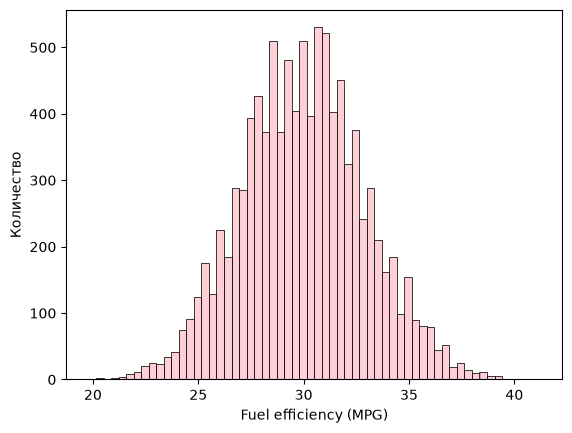

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(data['fuel_efficiency_mpg'], color='pink')

plt.xlabel('Fuel efficiency (MPG)')
plt.ylabel('Количество')
plt.show()

In [5]:
#числовая мера асимметрии распределения
data['fuel_efficiency_mpg'].skew()

np.float64(0.08080419601878173)

### **Задание 1.**
Узнаем, в каком столбце есть пропущенные значения.

In [6]:
data.isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

### **Задание 2.**
Узнаем, медианное значение столбца лошадиных сил.

<Axes: ylabel='horsepower'>

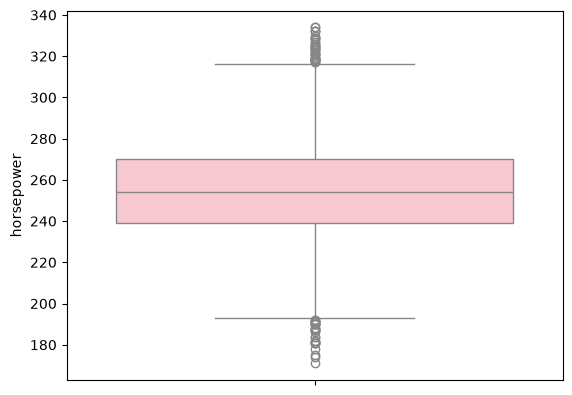

In [7]:
sns.boxplot(data=data, y='horsepower', color='pink')

In [8]:
data['horsepower'].median()

np.float64(254.0)

### **Разделение данных.**

In [9]:
#размер выборок
n = len(data)

n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

In [10]:
#перемешаем данные
np.random.seed(42)

idx = np.arange(n) #индексы строк таблицы
np.random.shuffle(idx)

In [11]:
#разеделим данные
df_train = data.iloc[idx[:n_train]]

df_val = data.iloc[idx[n_train:n_train + n_val]]

df_test = data.iloc[idx[n_train + n_val:]]

In [12]:
print('Train:', df_train.shape)
print('Validation:', df_val.shape)
print('Test:', df_test.shape)

Train: (6000, 5)
Validation: (2000, 5)
Test: (2000, 5)


### **Задание 3.**
Сравним две модели линейной регрессии. Одну обучим с заменой пропущенных значений на ноль, другую на среднее.

In [13]:
#обучение линейной модели
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T @ X
    XTX_inv = np.linalg.inv(XTX)
    w = XTX_inv @ X.T @ y

    return w[0], w[1:]

In [14]:
#рассчет ошибки
def rmse(y, y_pred):
    error = y - y_pred
    se = error ** 2
    mse = se.mean()
    return np.sqrt(mse)

_Заполним пропуски нулями._

In [15]:
#тренировочная
X_train_zero = df_train.fillna(0).drop(
    columns=['fuel_efficiency_mpg']
).values

y_train = df_train['fuel_efficiency_mpg'].values

#валидационная
X_val_zero = df_val.fillna(0).drop(
    columns=['fuel_efficiency_mpg']
).values

y_val = df_val['fuel_efficiency_mpg'].values

In [16]:
#обучим модель
w0, w = train_linear_regression(X_train_zero, y_train)

y_pred = w0 + X_val_zero @ w

score_zero = round(rmse(y_val, y_pred), 3)

print('RMSE с нулями:', score_zero)

RMSE с нулями: 2.205


_Заполним средним значением._

In [17]:
mean = df_train['horsepower'].mean()

#тренировочная
X_train_mean = df_train.fillna(mean).drop(
    columns=['fuel_efficiency_mpg']
).values

#валидационная
X_val_mean = df_val.fillna(mean).drop(
    columns=['fuel_efficiency_mpg']
).values

In [18]:
#обучим
w0, w = train_linear_regression(X_train_mean, y_train)

y_pred = w0 + X_val_mean @ w

score_mean = round(rmse(y_val, y_pred), 3)

print('RMSE со средним:', score_mean)

RMSE со средним: 2.202


### **Задание 4.**
Выберем лучший парамметр регуляризации.

In [19]:
#обучение модели с регуляризацией
def train_linear_regression_reg(X, y, r=0):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T @ X
    #добавление регуляризации
    XTX = XTX + r * np.eye(XTX.shape[0])

    w = np.linalg.inv(XTX) @ X.T @ y

    return w[0], w[1:]

In [20]:
#переберем разные значения
for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    w0, w = train_linear_regression_reg(X_train_zero, y_train, r=r)

    y_pred = w0 + X_val_zero @ w

    score = round(rmse(y_val, y_pred), 4)

    print(f'r = {r}: RMSE = {score}')

r = 0: RMSE = 2.2053
r = 0.01: RMSE = 2.2058
r = 0.1: RMSE = 2.2241
r = 1: RMSE = 2.3492
r = 5: RMSE = 2.4094
r = 10: RMSE = 2.4195
r = 100: RMSE = 2.4292


### **Задание 5.**
Проверим насколько модель зависит от случайного разделения данных.

In [23]:
#случайные значения
seeds = list(range(10))
print(seeds)

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


In [25]:
#заполним пропуски нулями
df_zeroes = data.fillna(0)

#замерим результаты
scores = []

for seed in seeds:
    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)

    #разделим
    df_train = df_zeroes.iloc[idx[:n_train]]
    df_val = df_zeroes.iloc[idx[n_train:n_train + n_val]]
    df_test = df_zeroes.iloc[idx[n_train + n_val:]]

    #тренировочная
    X_train = df_train.drop(
        columns=['fuel_efficiency_mpg']
    ).values

    y_train = df_train['fuel_efficiency_mpg'].values

    #валидационная
    X_val = df_val.drop(
        columns=['fuel_efficiency_mpg']
    ).values

    y_val = df_val['fuel_efficiency_mpg'].values

    #обучим
    w0, w = train_linear_regression(X_train, y_train)

    #предсказания
    y_pred = w0 + X_val @ w

    #сохраним RMSE
    score = rmse(y_val, y_pred)
    scores.append(score)

    print(f'seed = {seed}: RMSE = {score:.4f}')

#стандартное отклонение
std = round(np.std(scores), 3)

print('Стандартное отклонение:', std)


seed = 0: RMSE = 2.2392
seed = 1: RMSE = 2.2021
seed = 2: RMSE = 2.1634
seed = 3: RMSE = 2.2044
seed = 4: RMSE = 2.2019
seed = 5: RMSE = 2.2458
seed = 6: RMSE = 2.2697
seed = 7: RMSE = 2.1908
seed = 8: RMSE = 2.2166
seed = 9: RMSE = 2.2070
Standard deviation: 0.029


### **Задание 6.**
Обучим модель на 80% данных с регуляризацией 0.001 и посмотрим на результат.

In [26]:
#разделим
np.random.seed(9)

idx = np.arange(n)
np.random.shuffle(idx)

df_train = df_zeroes.iloc[idx[:n_train + n_val]]
df_test = df_zeroes.iloc[idx[n_train + n_val:]]

In [29]:
#обозначим таргет
#тренировочная
X_train = df_train.drop(
    columns=['fuel_efficiency_mpg']
).values

y_train = df_train['fuel_efficiency_mpg'].values

#тестовая
X_test = df_test.drop(
    columns=['fuel_efficiency_mpg']
).values

y_test = df_test['fuel_efficiency_mpg'].values

In [30]:
#обучаем модель
w0, w = train_linear_regression_reg(X_train, y_train, r=0.001)

#предсказания
y_pred = w0 + X_test @ w

#RMSE
score = rmse(y_test, y_pred)

print('RMSE:', round(score, 3))

RMSE: 2.236
